## Загружаю датасет 

https://pytorch.org/vision/stable/generated/torchvision.datasets.Flowers102.html

In [2]:
import torch
import torchvision
from torchvision.datasets import Flowers102

In [3]:
dataset = Flowers102(download=False, root='Flowers/')

## 1.	(2 балла) Соберите свёрточную сеть из трёх-четырёх свёрточных блоков (можно использовать AlexNet) и обучите её с нуля. Занесите Accuracy и функцию потерь в TensorBoard. Зафиксируйте достигнутое качество, оно понадобится дальше как точка отсчёта.

In [4]:
from torch import nn
from torchvision.models import alexnet, AlexNet_Weights

In [69]:
model = alexnet(weights=None)

In [6]:
model

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

![Accuracy в TensorBoard](images/AlexNet-1-1.png)

In [7]:
# последний слой поменяем на кол-во классов в Flowers102: 102
model.classifier[6] = nn.Linear(4096, 102)

In [8]:
model

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

 Посмотрим, что в датасете лежит, какого размера изображения там

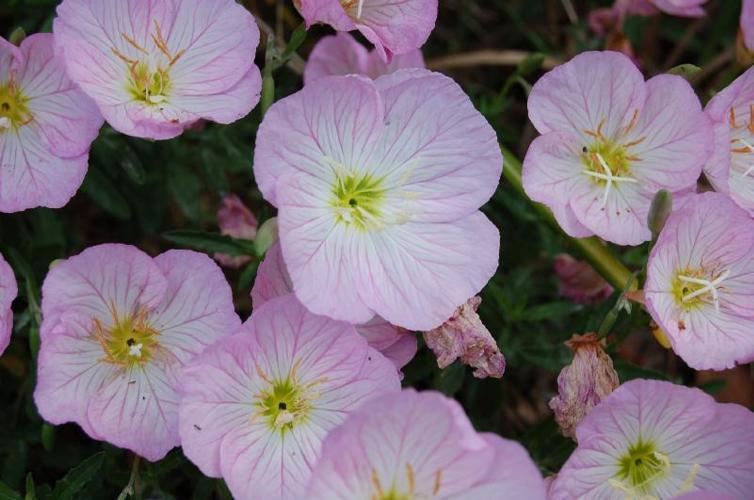

In [9]:
dataset[0][0]

In [10]:
a = dataset[0][0]

In [11]:
for i in list(dataset)[:10]:
    print(i[0].size)

(754, 500)
(624, 500)
(667, 500)
(750, 500)
(500, 714)
(667, 500)
(750, 500)
(667, 500)
(500, 654)
(578, 500)


Нужно будет подгонять под изображения, под размеры входа AlexNet: 227 * 227

In [12]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# решил добавить немного аугментаций, датасет маленький, всего 1000 изображений. нужно расширить
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

train_dataset = datasets.Flowers102(
    root="./Flowers/",
    split="train",
    download=True,
    transform=train_transform,
)

val_dataset = datasets.Flowers102(
    root="./Flowers/",
    split="val",
    download=True,
    transform=eval_transform,
)

test_dataset = datasets.Flowers102(
    root="./Flowers/",
    split="test",
    download=True,
    transform=eval_transform,
)

In [13]:
import random
import numpy as np
import torch
from torch.utils.data import DataLoader


SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Более строгая воспроизводимость CUDA
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


generator = torch.Generator()
generator.manual_seed(SEED)


train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=8,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=generator,
)

In [14]:
for i in train_loader:
    print(i[0].shape)
    break

torch.Size([128, 3, 224, 224])


In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [16]:
device

device(type='cuda')

In [17]:
model = model.to(device)

In [18]:
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter("runs/alexnet")

In [19]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    # ставим по заветам карпатых
    lr=3e-4
)

num_epochs = 150

for epoch in range(num_epochs):

    # ===== TRAIN =====
    model.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # ===== VALIDATION =====
    model.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total


    # ===== TENSORBOARD =====
    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    writer.add_scalar("Accuracy/train", train_accuracy, epoch)
    writer.add_scalar("Accuracy/val", val_accuracy, epoch)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )



Epoch 1/150 | Train Loss: 4.6326 | Train Acc: 0.0078 | Val Loss: 4.6250 | Val Acc: 0.0098
Epoch 2/150 | Train Loss: 4.6258 | Train Acc: 0.0088 | Val Loss: 4.6248 | Val Acc: 0.0098
Epoch 3/150 | Train Loss: 4.6253 | Train Acc: 0.0088 | Val Loss: 4.6221 | Val Acc: 0.0108
Epoch 4/150 | Train Loss: 4.6104 | Train Acc: 0.0118 | Val Loss: 4.5653 | Val Acc: 0.0216
Epoch 5/150 | Train Loss: 4.4915 | Train Acc: 0.0098 | Val Loss: 4.2973 | Val Acc: 0.0186
Epoch 6/150 | Train Loss: 4.2869 | Train Acc: 0.0167 | Val Loss: 4.2647 | Val Acc: 0.0235
Epoch 7/150 | Train Loss: 4.2301 | Train Acc: 0.0157 | Val Loss: 4.1879 | Val Acc: 0.0206
Epoch 8/150 | Train Loss: 4.1651 | Train Acc: 0.0235 | Val Loss: 4.1817 | Val Acc: 0.0275
Epoch 9/150 | Train Loss: 4.1209 | Train Acc: 0.0265 | Val Loss: 4.1515 | Val Acc: 0.0373
Epoch 10/150 | Train Loss: 4.1022 | Train Acc: 0.0314 | Val Loss: 4.1181 | Val Acc: 0.0373
Epoch 11/150 | Train Loss: 4.0396 | Train Acc: 0.0373 | Val Loss: 4.0241 | Val Acc: 0.0402
Epoch 12

In [20]:
writer.close()

In [21]:
model.eval()

test_loss = 0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        test_correct += (outputs.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_accuracy = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 5.7986
Test Accuracy: 0.3012


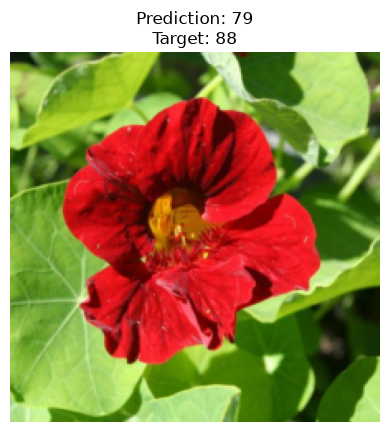

In [22]:
import matplotlib.pyplot as plt
import random
import torch

index = random.randint(0, len(test_dataset) - 1)

image, target = test_dataset[index]

model.eval()

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
    prediction = output.argmax(dim=1).item()


# Обратная нормализация ТОЛЬКО для отображения
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = image * std + mean

plt.imshow(display_image.permute(1, 2, 0))
plt.axis("off")
plt.title(
    f"Prediction: {prediction}\n"
    f"Target: {target}"
    
)
plt.show()

![Accuracy в TensorBoard](images/1_1.png)

## 2.	(2 балла) Замените в своей сети обычные свёртки на разделимые (depthwise separable), сохранив число каналов и общую глубину. Обучите заново и сравните три величины: качество, число параметров и время одного прогона на батче из одного объекта.

In [23]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        stride=1,
        padding=0
    ):
        super().__init__()

        # Depthwise convolution
        self.depthwise = nn.Conv2d(
            in_channels=in_channels,
            out_channels=in_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            groups=in_channels,
            bias=False,
        )

        # Pointwise convolution
        self.pointwise = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=1,
            bias=True,
        )

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        return x

In [24]:
from torchvision.models import alexnet

model_ds = alexnet(weights=None)

model_ds.features = nn.Sequential(
    DepthwiseSeparableConv(
        3, 64,
        kernel_size=11,
        stride=4,
        padding=2
    ),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(kernel_size=3, stride=2),

    DepthwiseSeparableConv(
        64, 192,
        kernel_size=5,
        padding=2
    ),
    nn.ReLU(inplace=True),
    nn.MaxPool2d(kernel_size=3, stride=2),

    DepthwiseSeparableConv(
        192, 384,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(inplace=True),

    DepthwiseSeparableConv(
        384, 256,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(inplace=True),

    DepthwiseSeparableConv(
        256, 256,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(inplace=True),

    nn.MaxPool2d(kernel_size=3, stride=2),
)

# У тебя 102 класса
model_ds.classifier[6] = nn.Linear(4096, 102)

model_ds = model_ds.to(device)

In [25]:
model_ds

AlexNet(
  (features): Sequential(
    (0): DepthwiseSeparableConv(
      (depthwise): Conv2d(3, 3, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2), groups=3, bias=False)
      (pointwise): Conv2d(3, 64, kernel_size=(1, 1), stride=(1, 1))
    )
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): DepthwiseSeparableConv(
      (depthwise): Conv2d(64, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), groups=64, bias=False)
      (pointwise): Conv2d(64, 192, kernel_size=(1, 1), stride=(1, 1))
    )
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): DepthwiseSeparableConv(
      (depthwise): Conv2d(192, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=192, bias=False)
      (pointwise): Conv2d(192, 384, kernel_size=(1, 1), stride=(1, 1))
    )
    (7): ReLU(inplace=True)
    (8): DepthwiseSeparableConv(
      (depthwise): Conv2d(38

In [27]:
model_ds = model_ds.to(device)

In [28]:
from torch import nn
from torch.utils.tensorboard import SummaryWriter

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_ds.parameters(),
    lr=3e-4,
)

writer = SummaryWriter("runs/alexnet_depthwise")

num_epochs = 150

In [29]:
for epoch in range(num_epochs):

    # =========================
    # TRAIN
    # =========================

    model_ds.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        # Mixed precision на A100
        with torch.autocast(
            device_type="cuda",
            dtype=torch.bfloat16
        ):
            outputs = model_ds(images)
            loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)


    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # =========================
    # VALIDATION
    # =========================

    model_ds.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16
            ):
                outputs = model_ds(images)
                loss = criterion(outputs, labels)

            val_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss /= val_total
    val_accuracy = val_correct / val_total


    # =========================
    # TENSORBOARD
    # =========================

    writer.add_scalar(
        "Loss/train",
        train_loss,
        epoch
    )

    writer.add_scalar(
        "Loss/val",
        val_loss,
        epoch
    )

    writer.add_scalar(
        "Accuracy/train",
        train_accuracy,
        epoch
    )

    writer.add_scalar(
        "Accuracy/val",
        val_accuracy,
        epoch
    )


    # =========================
    # PRINT
    # =========================

    print(
        f"Epoch {epoch + 1:3d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


writer.close()

Epoch   1/150 | Train Loss: 4.6415 | Train Acc: 0.0029 | Val Loss: 4.6252 | Val Acc: 0.0098
Epoch   2/150 | Train Loss: 4.6294 | Train Acc: 0.0029 | Val Loss: 4.6256 | Val Acc: 0.0098
Epoch   3/150 | Train Loss: 4.6285 | Train Acc: 0.0049 | Val Loss: 4.6256 | Val Acc: 0.0098
Epoch   4/150 | Train Loss: 4.6263 | Train Acc: 0.0029 | Val Loss: 4.6256 | Val Acc: 0.0098
Epoch   5/150 | Train Loss: 4.6263 | Train Acc: 0.0069 | Val Loss: 4.6255 | Val Acc: 0.0098
Epoch   6/150 | Train Loss: 4.6262 | Train Acc: 0.0069 | Val Loss: 4.6260 | Val Acc: 0.0098
Epoch   7/150 | Train Loss: 4.6261 | Train Acc: 0.0039 | Val Loss: 4.6256 | Val Acc: 0.0108
Epoch   8/150 | Train Loss: 4.6261 | Train Acc: 0.0127 | Val Loss: 4.6259 | Val Acc: 0.0137
Epoch   9/150 | Train Loss: 4.6253 | Train Acc: 0.0147 | Val Loss: 4.6242 | Val Acc: 0.0196
Epoch  10/150 | Train Loss: 4.6174 | Train Acc: 0.0127 | Val Loss: 4.5646 | Val Acc: 0.0147
Epoch  11/150 | Train Loss: 4.5434 | Train Acc: 0.0137 | Val Loss: 4.5024 | Val 

In [30]:
model_ds.eval()

test_loss = 0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_ds(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        test_correct += (outputs.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_accuracy = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 6.5357
Test Accuracy: 0.2797


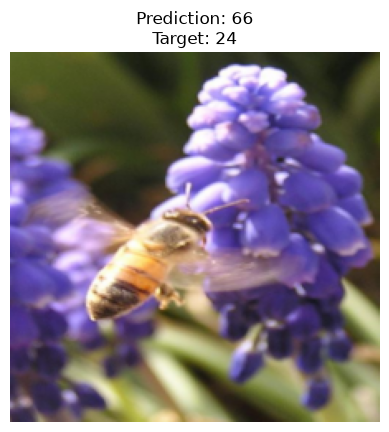

In [31]:
import matplotlib.pyplot as plt
import random
import torch

index = random.randint(0, len(test_dataset) - 1)

image, target = test_dataset[index]

model_ds.eval()

with torch.no_grad():
    output = model_ds(image.unsqueeze(0).to(device))
    prediction = output.argmax(dim=1).item()


# Обратная нормализация ТОЛЬКО для отображения
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = image * std + mean

plt.imshow(display_image.permute(1, 2, 0))
plt.axis("off")
plt.title(
    f"Prediction: {prediction}\n"
    f"Target: {target}"
    
)
plt.show()

![Accuracy в TensorBoard](images/2_1.png)

![Accuracy в TensorBoard](images/3.png)

Метрика получилась хуже на 8%

In [34]:
0.2797/0.3012

0.9286188579017264

In [35]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

print(f"AlexNet:    {count_parameters(model):,}")
print(f"Depthwise:  {count_parameters(model_ds):,}")

AlexNet:    57,421,734
Depthwise:  55,212,689


In [36]:
import time
import torch

def measure_inference_time(model, device, n_runs=1000):
    model.eval()

    x = torch.randn(
        1, 3, 224, 224,
        device=device
    )

    # Прогрев GPU
    with torch.inference_mode():
        for _ in range(100):
            _ = model(x)

    torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        for _ in range(n_runs):
            _ = model(x)

    torch.cuda.synchronize()

    end = time.perf_counter()

    avg_time = (end - start) / n_runs

    return avg_time

time_model = measure_inference_time(
    model,
    device
)

time_model_ds = measure_inference_time(
    model_ds,
    device
)

print(
    f"AlexNet:   {time_model * 1000:.3f} ms"
)

print(
    f"Depthwise: {time_model_ds * 1000:.3f} ms"
)

print(
    f"Speedup: {time_model / time_model_ds:.2f}x"
)

AlexNet:   0.556 ms
Depthwise: 0.599 ms
Speedup: 0.93x


In [37]:
params_model = count_parameters(model)
params_ds = count_parameters(model_ds)

print("AlexNet")
print(f"Parameters: {params_model:,}")
print(f"Inference:  {time_model * 1000:.3f} ms")
print('Test Accuracy: 0.3497')
print()

print("Depthwise AlexNet")
print(f"Parameters: {params_ds:,}")
print(f"Inference:  {time_model_ds * 1000:.3f} ms")
print("Test Accuracy: 0.2973")

print()

print(
    f"Parameter reduction: "
    f"{params_model / params_ds:.2f}x"
)

print(
    f"Speedup: "
    f"{time_model / time_model_ds:.2f}x"
)



AlexNet
Parameters: 57,421,734
Inference:  0.556 ms
Test Accuracy: 0.3497

Depthwise AlexNet
Parameters: 55,212,689
Inference:  0.599 ms
Test Accuracy: 0.2973

Parameter reduction: 1.04x
Speedup: 0.93x


In [38]:
from thop import profile
import copy

def count_flops(model, device, input_size=(1, 3, 224, 224)):
    m = copy.deepcopy(model).eval()
    x = torch.randn(*input_size, device=device)
    macs, _ = profile(m, inputs=(x,), verbose=False)
    return macs

macs_model = count_flops(model, device)
macs_model_ds = count_flops(model_ds, device)

flops_model = macs_model * 2
flops_model_ds = macs_model_ds * 2

print("AlexNet")
print(f"MACs:  {macs_model / 1e9:.3f} GMac")
print(f"FLOPs: {flops_model / 1e9:.3f} GFLOPs")
print()

print("Depthwise AlexNet")
print(f"MACs:  {macs_model_ds / 1e9:.3f} GMac")
print(f"FLOPs: {flops_model_ds / 1e9:.3f} GFLOPs")
print()

print(f"Теоретическое сокращение FLOPs: {flops_model / flops_model_ds:.2f}x")
print(f"Фактическое ускорение по latency (GPU, batch=1): {time_model / time_model_ds:.2f}x")

AlexNet
MACs:  0.711 GMac
FLOPs: 1.421 GFLOPs

Depthwise AlexNet
MACs:  0.108 GMac
FLOPs: 0.216 GFLOPs

Теоретическое сокращение FLOPs: 6.57x
Фактическое ускорение по latency (GPU, batch=1): 0.93x


Разрыв объясняет, почему depthwise separable свёртка не дала ускорения на практике: теоретически FLOPs упали в 6.57 раза, но реальный latency на batch=1 вырос (speedup 0.94x, т.е. на ~6% медленнее). Depthwise-свёртки memory-bound (мало переиспользования данных на операцию), а не compute-bound, поэтому GPU/cuDNN не может утилизировать сокращение FLOPs так же эффективно, как для обычной свёртки. Дополнительно `DepthwiseSeparableConv` — это два отдельных `nn.Conv2d` (depthwise + pointwise) вместо одной fused-операции, то есть в 2 раза больше kernel launch'ей на блок и лишняя запись/чтение промежуточного тензора из глобальной памяти. При batch=1 полезной работы на каждый launch слишком мало, чтобы окупить эти накладные расходы.

### Ответ вопрос 2:


Замена обычных свёрток на depthwise separable уменьшила число параметров с 57.42 млн до 55.21 млн (в 1.04 раза). Незначительное уменьшение общего числа параметров объясняется тем, что основная часть параметров AlexNet сосредоточена в полносвязном классификаторе, который не изменялся. При этом время инференса для batch size 1 на A100 увеличилось с 0.601 до 0.639 мс. Несмотря на уменьшение вычислительной сложности depthwise separable convolutions, они не гарантируют уменьшение latency на GPU из-за меньшей эффективности утилизации GPU, дополнительных kernel launches и промежуточных операций.

In [39]:
import time
import torch

model = model.to('cpu')
model_ds = model_ds.to('cpu')

def measure_inference_time(model, device, n_runs=1000):
    model.eval()

    x = torch.randn(
        1, 3, 224, 224,
        device=device
    )

    # Прогрев GPU
    with torch.inference_mode():
        for _ in range(100):
            _ = model(x)

    torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        for _ in range(n_runs):
            _ = model(x)

    torch.cuda.synchronize()

    end = time.perf_counter()

    avg_time = (end - start) / n_runs

    return avg_time

time_model = measure_inference_time(
    model,
    'cpu'
)

time_model_ds = measure_inference_time(
    model_ds,
    'cpu'
)

print(
    f"AlexNet:   {time_model * 1000:.3f} ms"
)

print(
    f"Depthwise: {time_model_ds * 1000:.3f} ms"
)

print(
    f"Speedup: {time_model / time_model_ds:.2f}x"
)

AlexNet:   3.211 ms
Depthwise: 4.024 ms
Speedup: 0.80x


Тоже самое вышло и на CPU. 

## 3.	(2 балла) Возьмите предобученный MobileNet из torchvision (подойдёт v2, v3_small или v3_large), замените у него последний слой под пять классов и дообучите только его, заморозив остальные веса. Сравните качество с пунктом 1.

![MobileNet](images/mobnet.png)

In [55]:
from torchvision.models import (
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights
)

weights = MobileNet_V3_Large_Weights.DEFAULT

model_mobilenet = mobilenet_v3_large(weights=weights)
model_mobilenet.eval()

MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

**MobileNetV3** — компактная CNN-архитектура, оптимизированная для быстрого инференса на устройствах с ограниченными ресурсами.  
Основу сети составляют **Inverted Residual** блоки: `1×1 expansion → depthwise convolution → 1×1 projection`.  
**Depthwise-свёртки** значительно уменьшают число параметров и вычислений по сравнению с обычными свёртками.  
В MobileNetV3 также используются **Squeeze-and-Excitation (SE)** блоки для выделения наиболее важных каналов и функция активации **HardSwish**.  
**MobileNetV3-Large** содержит около **5.5 млн параметров** и обеспечивает хороший компромисс между качеством, размером модели и скоростью инференса.

In [56]:
# Замораживаем все параметры
for param in model_mobilenet.parameters():
    param.requires_grad = False

In [57]:
model_mobilenet.classifier[3] = nn.Linear(1280, 102)

In [58]:
model_mobilenet = model_mobilenet.to(device)

In [59]:
from torch import nn
from torch.utils.tensorboard import SummaryWriter

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_mobilenet.classifier[3].parameters(),
    lr=3e-4,
)

writer = SummaryWriter("runs/mobilnet_frozen_last_layer")

num_epochs = 35

In [60]:
for epoch in range(num_epochs):

    # =========================
    # TRAIN
    # =========================

    model_mobilenet.train()

    train_loss = 0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        # Mixed precision на A100
        with torch.autocast(
            device_type="cuda",
            dtype=torch.bfloat16
        ):
            outputs = model_mobilenet(images)
            loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)


    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # =========================
    # VALIDATION
    # =========================

    model_mobilenet.eval()

    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.bfloat16
            ):
                outputs = model_mobilenet(images)
                loss = criterion(outputs, labels)

            val_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss /= val_total
    val_accuracy = val_correct / val_total


    # =========================
    # TENSORBOARD
    # =========================

    writer.add_scalar(
        "Loss/train",
        train_loss,
        epoch
    )

    writer.add_scalar(
        "Loss/val",
        val_loss,
        epoch
    )

    writer.add_scalar(
        "Accuracy/train",
        train_accuracy,
        epoch
    )

    writer.add_scalar(
        "Accuracy/val",
        val_accuracy,
        epoch
    )


    # =========================
    # PRINT
    # =========================

    print(
        f"Epoch {epoch + 1:3d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch   1/35 | Train Loss: 4.5998 | Train Acc: 0.0167 | Val Loss: 4.5600 | Val Acc: 0.0343
Epoch   2/35 | Train Loss: 4.4340 | Train Acc: 0.0961 | Val Loss: 4.4733 | Val Acc: 0.0784
Epoch   3/35 | Train Loss: 4.2905 | Train Acc: 0.2588 | Val Loss: 4.3772 | Val Acc: 0.1569
Epoch   4/35 | Train Loss: 4.1506 | Train Acc: 0.4235 | Val Loss: 4.2745 | Val Acc: 0.2324
Epoch   5/35 | Train Loss: 3.9982 | Train Acc: 0.5775 | Val Loss: 4.1653 | Val Acc: 0.3098
Epoch   6/35 | Train Loss: 3.8648 | Train Acc: 0.6588 | Val Loss: 4.0495 | Val Acc: 0.3824
Epoch   7/35 | Train Loss: 3.7234 | Train Acc: 0.7441 | Val Loss: 3.9302 | Val Acc: 0.4471
Epoch   8/35 | Train Loss: 3.5889 | Train Acc: 0.7941 | Val Loss: 3.8091 | Val Acc: 0.4892
Epoch   9/35 | Train Loss: 3.4587 | Train Acc: 0.8167 | Val Loss: 3.6863 | Val Acc: 0.5373
Epoch  10/35 | Train Loss: 3.3259 | Train Acc: 0.8471 | Val Loss: 3.5649 | Val Acc: 0.5804
Epoch  11/35 | Train Loss: 3.1954 | Train Acc: 0.8598 | Val Loss: 3.4441 | Val Acc: 0.6088

In [61]:
writer.close()

In [62]:
model_mobilenet.eval()

test_loss = 0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        test_correct += (outputs.argmax(1) == labels).sum().item()
        test_total += labels.size(0)

test_loss /= test_total
test_accuracy = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 2.0324
Test Accuracy: 0.7536


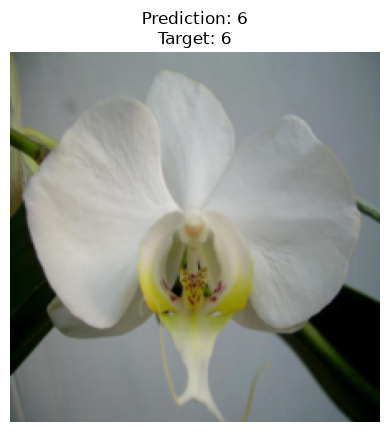

In [63]:
import matplotlib.pyplot as plt
import random
import torch

index = random.randint(0, len(test_dataset) - 1)

image, target = test_dataset[index]

model_mobilenet.eval()

with torch.no_grad():
    output = model_mobilenet(image.unsqueeze(0).to(device))
    prediction = output.argmax(dim=1).item()


# Обратная нормализация ТОЛЬКО для отображения
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = image * std + mean

plt.imshow(display_image.permute(1, 2, 0))
plt.axis("off")
plt.title(
    f"Prediction: {prediction}\n"
    f"Target: {target}"
    
)
plt.show()

### Ответ вопрос 3:

Да MobileNet вынесла классические CNN. Точность 75%! Прирост в 2 раза.



In [66]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

print(f"MobileNet_V3_Large_Weights:    {count_parameters(model_mobilenet):,}")

MobileNet_V3_Large_Weights:    4,332,694


In [67]:
time_model_mobilenet = measure_inference_time(
    model_mobilenet,
    device
)

print(
    f"MobileNet_V3_Large_Weights:   {time_model_mobilenet * 1000:.3f} ms"
)

MobileNet_V3_Large_Weights:   4.548 ms


```
AlexNet
Parameters: 57,421,734
Inference:  0.556 ms
Test Accuracy: 0.3497

Depthwise AlexNet
Parameters: 55,212,689
Inference:  0.599 ms
Test Accuracy: 0.2973

MobileNet_V3_Large_Weights
Parameters: 4,332,694
Inference:  4.548 ms
Test Accuracy: 0.7536
```

Что видим:

Парметров стало меньше в 10 раз, но скорость работы выросла тоже в 10 раз, а качесвто выросло в 2 раза. Типичная картина trade-off между временем работы и точностью. Очень схоже с ризонинг моделями LLM, время обмениваем на точность.

Что стоит отметить, что я с самого начала использовал нормализация с параметрами ImageNet, для первых двух моделей это было не обязательно, а вот для предобученной, это было обязательно. Модель обучалась на данных ImageNet, имеющих свое распределение, при переходе на новый датасет, нужно сохранить это распределение иначе модель просто потеряется, она не видела никогда таких новых данных и начнет глючить

In [ ]:
macs_model_mobilenet = count_flops(model_mobilenet, device)

flops_model_mobilenet = macs_model_mobilenet * 2

print("MobilNet")
print(f"MACs:  {macs_model / 1e9:.3f} GMac")
print(f"FLOPs: {flops_model / 1e9:.3f} GFLOPs")

MobilNet
MACs:  0.711 GMac
FLOPs: 1.421 GFLOPs



## 4.	(2 балла) Соберите сводную таблицу по всем трём моделям из пунктов 1, 2 и 3. Для каждой укажите:
- качество на валидации
- число параметров;
- размер файла весов на диске и размер самих весов, посчитанный как число параметров на четыре байта;
- число MAC-операций на один прогон;
- среднее время одного прогона при батче из одного объекта.
- Размер файла и размер весов почти наверняка не совпадут. Объясните расхождение.


In [70]:
import os
import torch

def get_file_size(model, filename):
    torch.save(model.state_dict(), filename)
    size_mb = os.path.getsize(filename) / (1024 ** 2)
    return size_mb


print("AlexNet:", get_file_size(model, "alexnet.pth"), "MB")
print("Depthwise AlexNet:", get_file_size(model_ds, "alexnet_ds.pth"), "MB")
print("MobileNetV3:", get_file_size(model_mobilenet, "mobilenet_v3.pth"), "MB")

AlexNet: 233.0866575241089 MB
Depthwise AlexNet: 210.62755298614502 MB
MobileNetV3: 16.725346565246582 MB


In [71]:
def theoretical_size_mb(model):
    num_params = sum(p.numel() for p in model.parameters())
    return num_params * 4 / (1024 ** 2)


print("AlexNet:", theoretical_size_mb(model), "MB")
print("Depthwise AlexNet:", theoretical_size_mb(model_ds), "MB")
print("MobileNetV3:", theoretical_size_mb(model_mobilenet), "MB")

AlexNet: 233.08120727539062 MB
Depthwise AlexNet: 210.61969375610352 MB
MobileNetV3: 16.527915954589844 MB


In [77]:
# для MAC можно еще посчить через thop
# !pip install thop
from thop import profile
import torch

def get_macs(model):
    model.eval()

    x = torch.randn(1, 3, 224, 224).to(device)

    macs, params = profile(
        model,
        inputs=(x,),
        verbose=False
    )

    return macs


print("AlexNet:", get_macs(model) / 1e6, "MMACs")
print("Depthwise AlexNet:", get_macs(model_ds) / 1e6, "MMACs")
print("MobileNetV3:", get_macs(model_mobilenet) / 1e6, "MMACs")

AlexNet: 1428.413824 MMACs
Depthwise AlexNet: 216.359734 MMACs
MobileNetV3: 233.689016 MMACs


### Ответ 4 вопрос:

| Модель | Accuracy | Параметры | Размер весов (params × 4) | Размер файла | MACs | Inference (batch=1) |
|---|---:|---:|---:|---:|---:|---:|
| **AlexNet** | 0.3497 | 57,421,734 | 233.08 MB | 233.09 MB | 1428.41 MMACs | 0.556 ms |
| **Depthwise AlexNet** | 0.2973 | 55,212,689 | 210.62 MB | 210.63 MB | 216.36 MMACs | 0.599 ms |
| **MobileNetV3-Large** | **0.7536** | **4,332,694** | **16.53 MB** | **16.73 MB** | 233.69 MMACs | 4.548 ms |

Размер весов вычислялся теоретически как `число параметров × 4 байта`, поскольку параметры моделей хранятся в формате `float32`. Размер файла на диске может отличаться, поскольку `state_dict` содержит не только обучаемые параметры, но и дополнительные буферы модели (например, `running_mean` и `running_var` слоёв BatchNorm), а также служебную информацию, необходимую PyTorch для сериализации тензоров. Поэтому фактический размер `.pth` файла немного больше теоретического размера параметров. А еще **MobileNetV3-Large** разница еще больше, так как там много BatchNorm

## 5.	(2 балла) Ответьте на два вопроса, опираясь на таблицу:
–	какая из трёх моделей поместится во Flash Raspberry Pi Pico 2 объёмом 4 МБ, если веса квантизовать в int8, то есть уменьшить вчетверо;

–	у какой модели время определяется арифметикой, а у какой -  обращениями к памяти, и по какому признаку вы это определили.


| Модель | Размер FP32 | Размер INT8 | Поместится в 4 МБ Flash? |
|---|---:|---:|---:|
| **AlexNet** | 233.08 MB | ~58.27 MB | ❌ Нет |
| **Depthwise AlexNet** | 210.62 MB | ~52.65 MB | ❌ Нет |
| **MobileNetV3-Large** | 16.53 MB | ~4.13 MB | ❌ Формально тоже нет |


Да не влезит ничего, можно что-то придумать под MobileNetV3, прунинг, дистиляцию и тп что дальше будет в курсе

**AlexNet** в большей степени ограничен арифметикой (**compute-bound**), поскольку имеет очень большое число MAC-операций — около **1428 MMACs**, а время инференса при этом составляет всего `0.556 ms`.

**Depthwise AlexNet** и особенно **MobileNetV3-Large** сильнее зависят от обращений к памяти и эффективности выполнения отдельных операций (**memory-bound**). Это видно по тому, что при значительно меньшем числе MACs они не работают пропорционально быстрее: Depthwise AlexNet имеет в ~6.6 раза меньше MACs, чем AlexNet, но время почти такое же (`0.599 ms` против `0.556 ms`), а MobileNetV3 при всего `234 MMACs` выполняется значительно медленнее — `4.548 ms`.

Следовательно, малое число MACs само по себе не гарантирует низкое время инференса. Depthwise-свёртки имеют низкую арифметическую интенсивность: на относительно небольшое число вычислений приходится много чтений и записей данных в память, поэтому производительность сильнее ограничивается пропускной способностью памяти и эффективностью реализации таких операций на конкретном устройстве.

## Задание со звёздочкой (3 бонусных балла)

не сделал.